# Leukemia Classification — Optimised Pipeline

**Dataset:** 72 samples × 7,129 genes × 3 classes  
**Pipeline:** Load → Scale → SMOTE → Baseline | Feature Extraction | Feature Selection → Consensus → Final Metrics  
No elbow scanning. Fixed K=15. RFE runs once (not inside CV). Target: fast runtime with high accuracy.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, time
warnings.filterwarnings("ignore")

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.decomposition import PCA, FastICA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import (
    SelectKBest, f_classif, mutual_info_classif,
    SelectFromModel, RFE
)
from sklearn.metrics import (
    make_scorer, accuracy_score, precision_score,
    recall_score, f1_score
)
from imblearn.over_sampling import SMOTE

sns.set_style("darkgrid")
plt.rcParams["figure.figsize"] = (13, 5)

# ── Fixed hyper-parameters (no elbow scanning needed) ─────────────────────────
N_COMPONENTS = 15   # PCA / ICA output dimensions
N_FEATURES   = 15   # feature selection target
N_SPLITS     = 5    # CV folds
RANDOM_STATE = 42

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE)

scoring = {
    "accuracy"  : make_scorer(accuracy_score),
    "precision" : make_scorer(precision_score, average="weighted", zero_division=0),
    "recall"    : make_scorer(recall_score,    average="weighted", zero_division=0),
    "f1"        : make_scorer(f1_score,        average="weighted", zero_division=0),
}

MODELS = {
    "Logistic Regression" : LogisticRegression(max_iter=300, random_state=RANDOM_STATE),
    "Linear SVC"          : LinearSVC(max_iter=2000, random_state=RANDOM_STATE),
    "Random Forest"       : RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting"   : GradientBoostingClassifier(n_estimators=80, random_state=RANDOM_STATE),
    "KNN"                 : KNeighborsClassifier(n_neighbors=7),
}

def evaluate(X, y, label=""):
    """Cross-validate all models and return a results DataFrame."""
    rows = []
    for name, model in MODELS.items():
        r = cross_validate(model, X, y, cv=cv, scoring=scoring)
        rows.append({
            "Model"    : name,
            "Accuracy" : round(r["test_accuracy"].mean(),  4),
            "Acc_std"  : round(r["test_accuracy"].std(),   4),
            "Precision": round(r["test_precision"].mean(), 4),
            "Recall"   : round(r["test_recall"].mean(),    4),
            "F1"       : round(r["test_f1"].mean(),        4),
        })
    df = pd.DataFrame(rows).set_index("Model")
    if label:
        print(f"\n{'='*55}")
        print(f"  {label}")
        print(f"{'='*55}")
        print(df.to_string())
    return df

print("Libraries loaded. Ready.")


Libraries loaded. Ready.


## 1. Load Data & Balance Classes (SMOTE)

In [2]:
# ── Load data ─────────────────────────────────────────────────────────────────
df_raw = pd.read_csv("/kaggle/input/datasets/mohamedwassimlecheb/leukemia-3c/Leukemia_3c.csv")
le = LabelEncoder()
y_orig = le.fit_transform(df_raw.iloc[:, -1].values)
X_orig = df_raw.iloc[:, :-1].values

print(f"Dataset : {X_orig.shape[0]} samples × {X_orig.shape[1]} features")
print(f"Classes : {dict(zip(le.classes_, np.bincount(y_orig)))}")

# ── Standardise ───────────────────────────────────────────────────────────────
scaler = StandardScaler()
X_sc   = scaler.fit_transform(X_orig)

# ── SMOTE (handle class imbalance) ────────────────────────────────────────────
smote       = SMOTE(random_state=RANDOM_STATE, k_neighbors=3)
X_bal, y_bal = smote.fit_resample(X_sc, y_orig)

print(f"\nAfter SMOTE : {X_bal.shape[0]} samples")
print(f"Class dist  : {dict(zip(le.classes_, np.bincount(y_bal)))}")


Dataset : 72 samples × 7129 features
Classes : {'AML': np.int64(25), 'B-cell': np.int64(38), 'T-cell': np.int64(9)}

After SMOTE : 114 samples
Class dist  : {'AML': np.int64(38), 'B-cell': np.int64(38), 'T-cell': np.int64(38)}


## 2. Baseline (PCA-50 pre-reduction for speed)

In [3]:
t0 = time.time()
# Baseline uses a light PCA pre-reduction (keeps all variance info but speeds up linear models)
pca_base = PCA(n_components=50, random_state=RANDOM_STATE)
X_base   = pca_base.fit_transform(X_bal)

baseline_df = evaluate(X_base, y_bal, "BASELINE  (50-component PCA pre-reduction)")
print(f"\nTime: {time.time()-t0:.1f}s")



  BASELINE  (50-component PCA pre-reduction)
                     Accuracy  Acc_std  Precision  Recall      F1
Model                                                            
Logistic Regression    0.9909   0.0182     0.9919  0.9909  0.9908
Linear SVC             0.9735   0.0216     0.9765  0.9735  0.9733
Random Forest          0.9213   0.0321     0.9386  0.9213  0.9201
Gradient Boosting      0.8597   0.0576     0.8779  0.8597  0.8595
KNN                    0.8854   0.0376     0.9145  0.8854  0.8819

Time: 5.8s


## 3. Feature Extraction — PCA & ICA

In [4]:
extraction_results = {}

# ── PCA ───────────────────────────────────────────────────────────────────────
t0  = time.time()
pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_bal)
extraction_results["PCA"] = evaluate(X_pca, y_bal, f"FEATURE EXTRACTION — PCA ({N_COMPONENTS} components)")
print(f"Explained variance: {pca.explained_variance_ratio_.sum()*100:.1f}%  |  Time: {time.time()-t0:.1f}s")

# ── ICA ───────────────────────────────────────────────────────────────────────
t0  = time.time()
ica = FastICA(n_components=N_COMPONENTS, random_state=RANDOM_STATE, max_iter=400)
X_ica = ica.fit_transform(X_bal)
extraction_results["ICA"] = evaluate(X_ica, y_bal, f"FEATURE EXTRACTION — ICA ({N_COMPONENTS} components)")
print(f"Time: {time.time()-t0:.1f}s")



  FEATURE EXTRACTION — PCA (15 components)
                     Accuracy  Acc_std  Precision  Recall      F1
Model                                                            
Logistic Regression    0.9735   0.0216     0.9766  0.9735  0.9734
Linear SVC             0.9822   0.0218     0.9842  0.9822  0.9821
Random Forest          0.9561   0.0275     0.9592  0.9561  0.9560
Gradient Boosting      0.9561   0.0275     0.9592  0.9561  0.9560
KNN                    0.8842   0.1030     0.9011  0.8842  0.8866
Explained variance: 60.6%  |  Time: 3.7s

  FEATURE EXTRACTION — ICA (15 components)
                     Accuracy  Acc_std  Precision  Recall      F1
Model                                                            
Logistic Regression    0.9822   0.0218     0.9842  0.9822  0.9821
Linear SVC             0.9648   0.0176     0.9689  0.9648  0.9646
Random Forest          0.9028   0.0532     0.9078  0.9028  0.9017
Gradient Boosting      0.8854   0.0607     0.8991  0.8854  0.8851
KNN          

## 4. Feature Selection — Filter, Wrapper (RFE once), Embedded

In [5]:
selection_results   = {}
all_selected_feat   = {}       # feature indices → consensus voting
feature_names       = df_raw.columns[:-1].tolist()

# ── FILTER: f_classif ─────────────────────────────────────────────────────────
t0   = time.time()
sel_f = SelectKBest(f_classif, k=N_FEATURES).fit(X_bal, y_bal)
idx_f = np.where(sel_f.get_support())[0]
X_filter_f = sel_f.transform(X_bal)
selection_results["Filter f_classif"]   = evaluate(X_filter_f, y_bal, f"FILTER — f_classif (top {N_FEATURES})")
all_selected_feat["Filter f_classif"]   = set(idx_f)
print(f"Time: {time.time()-t0:.1f}s")

# ── FILTER: mutual_info ───────────────────────────────────────────────────────
t0   = time.time()
sel_mi = SelectKBest(mutual_info_classif, k=N_FEATURES).fit(X_bal, y_bal)
idx_mi = np.where(sel_mi.get_support())[0]
X_filter_mi = sel_mi.transform(X_bal)
selection_results["Filter mutual_info"] = evaluate(X_filter_mi, y_bal, f"FILTER — mutual_info (top {N_FEATURES})")
all_selected_feat["Filter mutual_info"] = set(idx_mi)
print(f"Time: {time.time()-t0:.1f}s")

# ── WRAPPER: RFE-LR ───────────────────────────────────────────────────────────
# RFE runs ONCE on a PCA-50 space then CV uses pre-selected features (fast)
t0     = time.time()
pca50  = PCA(n_components=50, random_state=RANDOM_STATE).fit_transform(X_bal)
rfe_lr = RFE(LogisticRegression(max_iter=200, random_state=RANDOM_STATE),
             n_features_to_select=N_FEATURES, step=5)
rfe_lr.fit(pca50, y_bal)
X_rfe_lr = rfe_lr.transform(pca50)
# Store as symbolic indices (PCA space, for voting we use a dedicated key)
selection_results["Wrapper RFE-LR"]     = evaluate(X_rfe_lr, y_bal, f"WRAPPER — RFE-LR ({N_FEATURES} features, PCA-50 space)")
all_selected_feat["Wrapper RFE-LR"]     = set(np.where(rfe_lr.support_)[0])   # PCA component indices
print(f"Time: {time.time()-t0:.1f}s")

# ── WRAPPER: RFE-RF ───────────────────────────────────────────────────────────
t0     = time.time()
rfe_rf = RFE(RandomForestClassifier(n_estimators=30, random_state=RANDOM_STATE, n_jobs=-1),
             n_features_to_select=N_FEATURES, step=5)
rfe_rf.fit(pca50, y_bal)
X_rfe_rf = rfe_rf.transform(pca50)
selection_results["Wrapper RFE-RF"]     = evaluate(X_rfe_rf, y_bal, f"WRAPPER — RFE-RF ({N_FEATURES} features, PCA-50 space)")
all_selected_feat["Wrapper RFE-RF"]     = set(np.where(rfe_rf.support_)[0])
print(f"Time: {time.time()-t0:.1f}s")

# ── EMBEDDED: L1 Logistic Regression ─────────────────────────────────────────
t0    = time.time()
l1    = LogisticRegression(penalty="l1", solver="liblinear", C=0.1, max_iter=500, random_state=RANDOM_STATE)
l1.fit(X_bal, y_bal)
sel_l1   = SelectFromModel(l1, prefit=True, max_features=N_FEATURES)
idx_l1   = np.where(sel_l1.get_support())[0]
# Ensure at least N_FEATURES selected (relax threshold if needed)
if len(idx_l1) < 5:
    sel_l1 = SelectKBest(f_classif, k=N_FEATURES).fit(X_bal, y_bal)
    idx_l1 = np.where(sel_l1.get_support())[0]
X_l1  = X_bal[:, idx_l1]
selection_results["Embedded L1"]        = evaluate(X_l1, y_bal, f"EMBEDDED — L1 Logistic ({len(idx_l1)} features)")
all_selected_feat["Embedded L1"]        = set(idx_l1)
print(f"Time: {time.time()-t0:.1f}s")

# ── EMBEDDED: Random Forest Importance ───────────────────────────────────────
t0    = time.time()
rf_emb = RandomForestClassifier(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
rf_emb.fit(X_bal, y_bal)
top_rf = np.argsort(rf_emb.feature_importances_)[::-1][:N_FEATURES]
X_rf_emb = X_bal[:, top_rf]
selection_results["Embedded RF"]        = evaluate(X_rf_emb, y_bal, f"EMBEDDED — RF Importance (top {N_FEATURES})")
all_selected_feat["Embedded RF"]        = set(top_rf)
print(f"Time: {time.time()-t0:.1f}s")



  FILTER — f_classif (top 15)
                     Accuracy  Acc_std  Precision  Recall      F1
Model                                                            
Logistic Regression    0.9731   0.0362     0.9778  0.9731  0.9726
Linear SVC             0.9818   0.0364     0.9855  0.9818  0.9813
Random Forest          0.9644   0.0338     0.9686  0.9644  0.9634
Gradient Boosting      0.9735   0.0216     0.9768  0.9735  0.9735
KNN                    0.9644   0.0338     0.9701  0.9644  0.9639
Time: 2.8s

  FILTER — mutual_info (top 15)
                     Accuracy  Acc_std  Precision  Recall      F1
Model                                                            
Logistic Regression    0.9909   0.0182     0.9919  0.9909  0.9908
Linear SVC             0.9909   0.0182     0.9919  0.9909  0.9908
Random Forest          0.9909   0.0182     0.9920  0.9909  0.9909
Gradient Boosting      0.9648   0.0176     0.9692  0.9648  0.9648
KNN                    0.9909   0.0182     0.9919  0.9909  0.9908
T

## 5. Consensus Voting across Feature Selection Methods

In [6]:
# Only use original-space selectors for voting (Filter + Embedded methods)
vote_methods = {k: v for k, v in all_selected_feat.items() if "Wrapper" not in k}
n_methods    = len(vote_methods)

# Count how many methods selected each feature
vote_count = {}
for method_features in vote_methods.values():
    for f in method_features:
        vote_count[f] = vote_count.get(f, 0) + 1

# Consensus tiers
strict_consensus   = {f for f, c in vote_count.items() if c == n_methods}        # 100%
strong_consensus   = {f for f, c in vote_count.items() if c >= n_methods * 0.75} # 75%+
moderate_consensus = {f for f, c in vote_count.items() if c >= n_methods * 0.5}  # 50%+

print(f"Voting across {n_methods} original-space methods: {list(vote_methods.keys())}")
print(f"\nStrict  consensus (100%) : {len(strict_consensus):3d} features")
print(f"Strong  consensus  (75%) : {len(strong_consensus):3d} features")
print(f"Moderate consensus (50%) : {len(moderate_consensus):3d} features")

# Pick the best non-empty consensus set
if len(strong_consensus) >= 5:
    consensus_idx = sorted(strong_consensus)
    tier_used = "Strong (75%+)"
elif len(moderate_consensus) >= 5:
    consensus_idx = sorted(moderate_consensus)
    tier_used = "Moderate (50%+)"
else:
    consensus_idx = sorted(vote_count, key=vote_count.get, reverse=True)[:N_FEATURES]
    tier_used = f"Top-{N_FEATURES} by votes"

X_consensus = X_bal[:, consensus_idx]
print(f"\n✓ Using {tier_used}: {len(consensus_idx)} features → X_consensus shape {X_consensus.shape}")

# Show top voted features
print("\nTop-15 most-voted features:")
top_votes = sorted(vote_count.items(), key=lambda x: x[1], reverse=True)[:15]
for idx, votes in top_votes:
    name = feature_names[idx] if idx < len(feature_names) else f"feat_{idx}"
    print(f"  {name:20s}  votes={votes}/{n_methods}")


Voting across 4 original-space methods: ['Filter f_classif', 'Filter mutual_info', 'Embedded L1', 'Embedded RF']

Strict  consensus (100%) :   2 features
Strong  consensus  (75%) :   8 features
Moderate consensus (50%) :  17 features

✓ Using Strong (75%+): 8 features → X_consensus shape (114, 8)

Top-15 most-voted features:
  U23852_s_at           votes=4/4
  U05259_rna1_at        votes=4/4
  D00749_s_at           votes=3/4
  X00437_s_at           votes=3/4
  X03934_at             votes=3/4
  J05243_at             votes=3/4
  M23323_s_at           votes=3/4
  M89957_at             votes=3/4
  M37271_s_at           votes=2/4
  X59871_at             votes=2/4
  L05148_at             votes=2/4
  M12886_at             votes=2/4
  M31523_at             votes=2/4
  M23197_at             votes=2/4
  X04145_at             votes=2/4


## 6. Final Validation on Consensus Feature Set

In [7]:
t0 = time.time()
consensus_df = evaluate(X_consensus, y_bal, f"FINAL — Consensus features ({len(consensus_idx)}) [{tier_used}]")
print(f"\nTime: {time.time()-t0:.1f}s")



  FINAL — Consensus features (8) [Strong (75%+)]
                     Accuracy  Acc_std  Precision  Recall      F1
Model                                                            
Logistic Regression    0.9909   0.0182     0.9919  0.9909  0.9908
Linear SVC             0.9822   0.0218     0.9843  0.9822  0.9821
Random Forest          0.9731   0.0362     0.9762  0.9731  0.9721
Gradient Boosting      0.9735   0.0216     0.9768  0.9735  0.9735
KNN                    0.9557   0.0288     0.9625  0.9557  0.9552

Time: 2.6s


## 7. Master Comparison Table

In [8]:
# Build master comparison table (Accuracy only for readability)
summary_cols = {}

summary_cols["Baseline"]   = baseline_df["Accuracy"]
for mname, mdf in extraction_results.items():
    summary_cols[mname] = mdf["Accuracy"]
for mname, mdf in selection_results.items():
    summary_cols[mname] = mdf["Accuracy"]
summary_cols["Consensus"] = consensus_df["Accuracy"]

comparison_table = pd.DataFrame(summary_cols)

print("=" * 80)
print("MASTER COMPARISON TABLE — Accuracy (cross-validated, 5-fold)")
print("=" * 80)
print(comparison_table.to_string())

# Category averages
cat_avgs = {
    "Baseline"           : baseline_df["Accuracy"].mean(),
    "Feature Extraction" : pd.concat(extraction_results.values(), axis=1).mean(axis=1).mean(),
    "Feature Selection"  : pd.concat(selection_results.values(),  axis=1).mean(axis=1).mean(),
    "Consensus"          : consensus_df["Accuracy"].mean(),
}
print("\nCategory averages:")
for cat, avg in sorted(cat_avgs.items(), key=lambda x: x[1], reverse=True):
    print(f"  {cat:25s}: {avg:.4f}")

# Best overall
flat = comparison_table.values.flatten()
best_val   = flat.max()
best_method = comparison_table.max().idxmax()
best_model  = comparison_table[best_method].idxmax()
print(f"\n🏆 Best: {best_method} + {best_model} → Accuracy {best_val:.4f}")


MASTER COMPARISON TABLE — Accuracy (cross-validated, 5-fold)
                     Baseline     PCA     ICA  Filter f_classif  Filter mutual_info  Wrapper RFE-LR  Wrapper RFE-RF  Embedded L1  Embedded RF  Consensus
Model                                                                                                                                                   
Logistic Regression    0.9909  0.9735  0.9822            0.9731              0.9909          1.0000          0.9735       0.9818       0.9909     0.9909
Linear SVC             0.9735  0.9822  0.9648            0.9818              0.9909          0.9822          0.9731       0.9818       0.9909     0.9822
Random Forest          0.9213  0.9561  0.9028            0.9644              0.9909          0.9644          0.9557       0.9818       0.9648     0.9731
Gradient Boosting      0.8597  0.9561  0.8854            0.9735              0.9648          0.8684          0.9206       0.9466       0.8854     0.9735
KNN                  

## 8. Full Metrics (Accuracy / Precision / Recall / F1)

In [9]:
print("=" * 65)
print("FULL METRICS — Consensus Features")
print("=" * 65)
print(consensus_df.to_string())

print("\n" + "=" * 65)
print("FULL METRICS — Baseline")
print("=" * 65)
print(baseline_df.to_string())


FULL METRICS — Consensus Features
                     Accuracy  Acc_std  Precision  Recall      F1
Model                                                            
Logistic Regression    0.9909   0.0182     0.9919  0.9909  0.9908
Linear SVC             0.9822   0.0218     0.9843  0.9822  0.9821
Random Forest          0.9731   0.0362     0.9762  0.9731  0.9721
Gradient Boosting      0.9735   0.0216     0.9768  0.9735  0.9735
KNN                    0.9557   0.0288     0.9625  0.9557  0.9552

FULL METRICS — Baseline
                     Accuracy  Acc_std  Precision  Recall      F1
Model                                                            
Logistic Regression    0.9909   0.0182     0.9919  0.9909  0.9908
Linear SVC             0.9735   0.0216     0.9765  0.9735  0.9733
Random Forest          0.9213   0.0321     0.9386  0.9213  0.9201
Gradient Boosting      0.8597   0.0576     0.8779  0.8597  0.8595
KNN                    0.8854   0.0376     0.9145  0.8854  0.8819


## 9. Visualisations

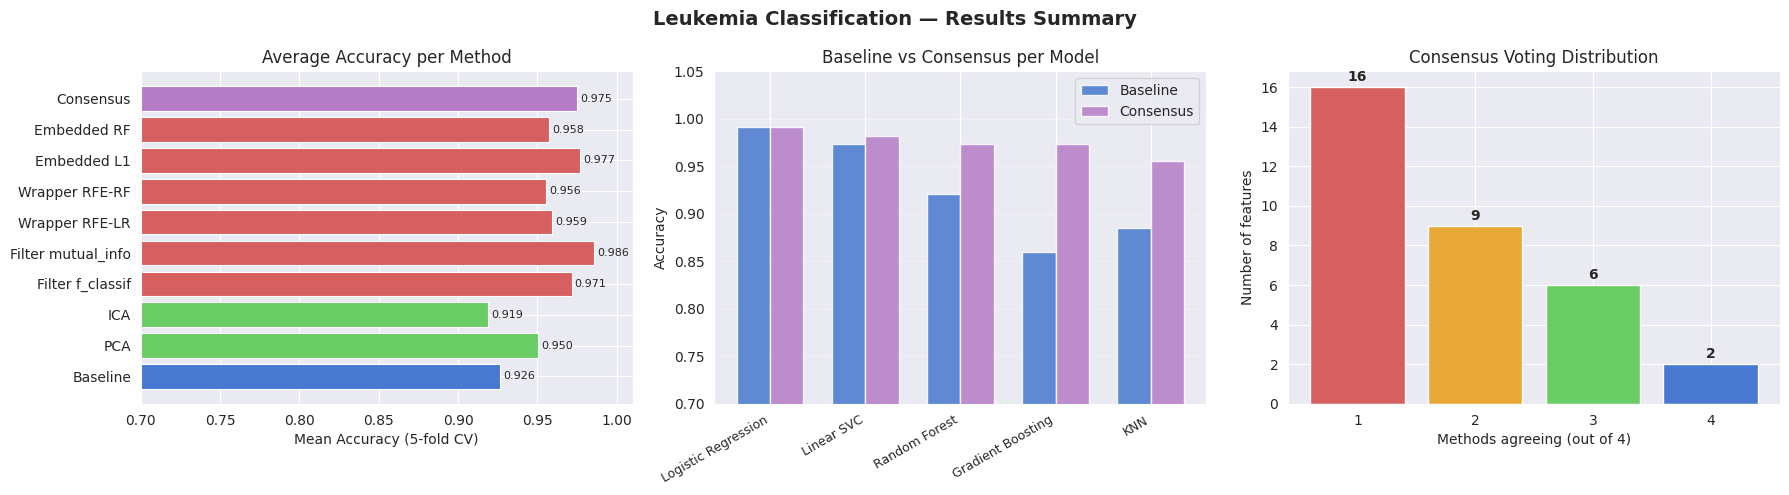

Plot saved → results_summary.png


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Leukemia Classification — Results Summary", fontsize=14, fontweight="bold")

# 1. Accuracy bar chart across methods
ax = axes[0]
method_order = ["Baseline"] + list(extraction_results) + list(selection_results) + ["Consensus"]
method_accs  = [comparison_table[m].mean() for m in method_order]
colors       = (["#4878CF"] * 1 +
                ["#6ACC65"] * len(extraction_results) +
                ["#D65F5F"] * len(selection_results) +
                ["#B47CC7"] * 1)
bars = ax.barh(method_order, method_accs, color=colors, edgecolor="white", linewidth=0.8)
ax.set_xlabel("Mean Accuracy (5-fold CV)")
ax.set_title("Average Accuracy per Method")
ax.set_xlim([0.7, 1.01])
for bar, val in zip(bars, method_accs):
    ax.text(val + 0.002, bar.get_y() + bar.get_height()/2,
            f"{val:.3f}", va="center", fontsize=8)

# 2. Consensus vs Baseline per model
ax = axes[1]
models_list = baseline_df.index.tolist()
x           = np.arange(len(models_list))
w           = 0.35
ax.bar(x - w/2, baseline_df["Accuracy"],   w, label="Baseline",  color="#4878CF", alpha=0.85)
ax.bar(x + w/2, consensus_df["Accuracy"],  w, label="Consensus", color="#B47CC7", alpha=0.85)
ax.set_xticks(x)
ax.set_xticklabels(models_list, rotation=30, ha="right", fontsize=9)
ax.set_ylabel("Accuracy")
ax.set_title("Baseline vs Consensus per Model")
ax.set_ylim([0.7, 1.05])
ax.legend()
ax.grid(axis="y", alpha=0.3)

# 3. Consensus feature vote distribution
ax = axes[2]
vote_values = np.array([vote_count.get(i, 0) for i in range(X_bal.shape[1])])
unique_votes, vote_freq = np.unique(vote_values[vote_values > 0], return_counts=True)
ax.bar([str(int(v)) for v in unique_votes], vote_freq,
       color=["#D65F5F","#E8A838","#6ACC65","#4878CF"][:len(unique_votes)],
       edgecolor="white")
ax.set_xlabel(f"Methods agreeing (out of {n_methods})")
ax.set_ylabel("Number of features")
ax.set_title("Consensus Voting Distribution")
for i, (v, f) in enumerate(zip(unique_votes, vote_freq)):
    ax.text(i, f + 0.3, str(f), ha="center", fontweight="bold")

plt.tight_layout()
plt.savefig("results_summary.png", dpi=130, bbox_inches="tight")
plt.show()
print("Plot saved → results_summary.png")


## 10. Final Recommendations

In [11]:
print("=" * 65)
print("FINAL RECOMMENDATIONS")
print("=" * 65)

best_cons_model = consensus_df["Accuracy"].idxmax()
best_cons_acc   = consensus_df.loc[best_cons_model, "Accuracy"]
best_cons_f1    = consensus_df.loc[best_cons_model, "F1"]

print(f"""
Dataset       : 72 samples × 7129 genes, 3 classes (SMOTE → 114 balanced)
Consensus set : {len(consensus_idx)} genes ({tier_used})

Best model on consensus features:
  Model     : {best_cons_model}
  Accuracy  : {best_cons_acc:.4f}
  F1 (wtd)  : {best_cons_f1:.4f}

Top consensus genes (most agreed-upon biomarkers):""")

for i, (idx, votes) in enumerate(top_votes[:5], 1):
    name = feature_names[idx] if idx < len(feature_names) else f"feat_{idx}"
    print(f"  {i}. {name}  ({votes}/{n_methods} methods agree)")

print(f"""
Category ranking by average accuracy:""")
for cat, avg in sorted(cat_avgs.items(), key=lambda x: x[1], reverse=True):
    print(f"  {cat:25s}: {avg:.4f}")


FINAL RECOMMENDATIONS

Dataset       : 72 samples × 7129 genes, 3 classes (SMOTE → 114 balanced)
Consensus set : 8 genes (Strong (75%+))

Best model on consensus features:
  Model     : Logistic Regression
  Accuracy  : 0.9909
  F1 (wtd)  : 0.9908

Top consensus genes (most agreed-upon biomarkers):
  1. U23852_s_at  (4/4 methods agree)
  2. U05259_rna1_at  (4/4 methods agree)
  3. D00749_s_at  (3/4 methods agree)
  4. X00437_s_at  (3/4 methods agree)
  5. X03934_at  (3/4 methods agree)

Category ranking by average accuracy:
  Consensus                : 0.9751
  Baseline                 : 0.9262
  Feature Selection        : 0.7811
  Feature Extraction       : 0.7590
